# Capstone — Sleep staging (Sleep-EDF)

### Real-data capstone companion · *Biomedical Signal Processing & Data Analytics*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farhad-abtahi/CM2013/blob/main/notebooks/track_sleep_edf.ipynb) [![View](https://img.shields.io/badge/view-static-orange)](https://farhad-abtahi.github.io/CM2013/nb/track_sleep_edf.html) [![JupyterLite](https://img.shields.io/badge/run-JupyterLite-blue)](https://farhad-abtahi.github.io/CM2013/lite/lab/index.html?path=track_sleep_edf.ipynb)

> **Motivating question.** Does the pipeline you built on synthetic EEG still hold up on real overnight recordings with messy R&K labels and a subject split?

## What this notebook demonstrates

- Sleep-EDF Expanded end-to-end (PhysioNet, ODC-BY) via `mne`.
- R&K → AASM label handling (merge S3+S4 → N3; drop Movement/Unknown).
- The leakage rule that matters here: **split by _subject_, not night**.
- Honest panel (κ, macro-F1, confusion) under leave-one-subject-out + a hypnogram.

## What you'll do

You'll stage real Sleep-EDF PSG recordings end to end — extract EEG/EOG/EMG features, classify sleep stages with leave-one-subject-out validation, and read Cohen's kappa against the human inter-rater ceiling (≈ 0.76).

## Runs in

| Platform | Status |
|---|---|
| **View (static) / CI** | full pipeline on **synthetic** data (no network) |
| **Google Colab** | set `USE_REAL = True` for the real download |
| **JupyterLite** | synthetic path only |

**Split unit:** **subject**.  **Default metric:** Cohen's κ.  *Real download is slow (PhysioNet); 2–3 subjects is enough to see the split work.*

## 0 · Background & literature review (do this first — course outcome L5)

**Course refresher:** EEG/EOG/EMG signatures §1.4 · epoching Ch2 · spindle STFT/wavelets §3.9/§5.3 · band power via Welch/multitaper §7.5–7.6 · the sleep feature set §11.4 · Cohen's κ §12.5 · epochs→hypnogram §12.6. **Anchors:** Kemp et al. (2000); AASM scoring manual; Supratak (DeepSleepNet) / Perslev (U-Sleep).

**Guiding questions your report must answer** (motivate your design — see [`tracks/BACKGROUND_MAP.md`](https://github.com/farhad-abtahi/CM2013/blob/main/tracks/BACKGROUND_MAP.md)):

- What AASM rules separate N2 from N3, and which feature carries REM vs Wake?
- Why is N1 the hardest stage, and what κ (~0.76) do *human* scorers reach?
- Why must the split be subject-wise (two nights per subject)?

In [1]:
%matplotlib inline
import sys, os, subprocess

def _add_paths(root):
    for sub in ("tracks", "src", "src/bsp"):
        p = os.path.join(root, sub)
        if os.path.isdir(p):
            sys.path.insert(0, os.path.abspath(p))

# Local checkout: repo root is the parent of notebooks/ (or the cwd itself).
_add_paths(".."); _add_paths(".")
try:
    from sleep_edf import SleepEDFTrack
    import bookstyle as bs   # shared plotting style
except Exception:
    if "google.colab" in sys.modules:
        # imbalanced-learn is NOT pre-installed in a fresh Colab runtime, and the
        # decision-points A/B below runs cfg={"imbalance": "smote"} -- so it goes
        # in here, not in a comment, or that cell raises ImportError on first run.
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "mne", "scikit-learn", "imbalanced-learn"], check=False)
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/farhad-abtahi/CM2013", "_bsp_repo"], check=False)
    _add_paths("_bsp_repo")
    from sleep_edf import SleepEDFTrack
    import bookstyle as bs

import numpy as np
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
# SYNTHETIC by default so the static view / CI / JupyterLite render WITHOUT network.
# Set USE_REAL = True in Colab to download and run the real dataset.
USE_REAL = True
print("environment :", "colab" if IN_COLAB else sys.platform)
print("USE_REAL    :", USE_REAL, "(synthetic fallback renders offline)")


environment : win32
USE_REAL    : True (synthetic fallback renders offline)


## ✍️ Predict before you run

On the real data, will Cohen's **κ** be higher or lower than the synthetic smoke's ≈ 0.6? Which single stage will have the **worst** recall? Will accuracy be higher or lower than κ — and why? And how far apart will the **best and worst subject** be?

*Write your prediction down now. The point is to be surprised when you are wrong — that is where the intuition forms.*

## 1 · Get the data (real or synthetic)

Synthetic `smoke()` is the offline default; the real path downloads a small Sleep-Cassette subset via `mne` and caches it.

In [2]:
track = SleepEDFTrack()
if USE_REAL:
    cache = os.path.join('..', 'data_cache', 'sleep_edf') if os.path.isdir('../data_cache') else 'data_cache/sleep_edf'
    track.download(cache, subset=[0, 1, 2]); recs = track.load(cache)
else:
    recs = track.smoke()
print('recordings:', len(recs), '| subjects:', sorted({r.group for r in recs}))

c:\Users\inema\OneDrive\Dokumenter\KTH\4.aar\signal_processing\project\capstone-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


recordings: 6 | subjects: ['SC400', 'SC401', 'SC402']


In [3]:
from sleep_crop import crop_to_sleep, stage_counts

recs_full = recs                                  # keep the uncropped nights
recs = [crop_to_sleep(r) for r in recs_full]      # from here on: cropped nights

print("Before cropping:", stage_counts(recs_full))
print("After cropping :", stage_counts(recs))
for r, c in zip(recs_full, recs):
    print(r.meta["record"], r.group,
          f"{len(r.labels)*30/3600:.1f} h -> {len(c.labels)*30/3600:.1f} h")

Before cropping: {np.str_('N1'): '596 (4 %)', np.str_('N2'): '2792 (17 %)', np.str_('N3'): '932 (6 %)', np.str_('REM'): '1028 (6 %)', np.str_('W'): '11340 (68 %)'}
After cropping : {np.str_('N1'): '596 (9 %)', np.str_('N2'): '2792 (44 %)', np.str_('N3'): '932 (15 %)', np.str_('REM'): '1028 (16 %)', np.str_('W'): '943 (15 %)'}
SC4001E0 SC400 22.1 h -> 7.0 h
SC4002E0 SC400 23.6 h -> 9.4 h
SC4011E0 SC401 23.4 h -> 9.2 h
SC4012E0 SC401 23.7 h -> 9.9 h
SC4021E0 SC402 23.4 h -> 8.5 h
SC4022E0 SC402 23.0 h -> 8.4 h


In [4]:
# Same setup as iteration 2 (imbalance="none"); only the cropping changes
for name, rs in [("uncropped", recs_full), ("cropped ±30 min", recs)]:
    Xc, yc, gc = track.build_dataset(rs)
    r = track.evaluate(Xc, yc, gc, cfg={"imbalance": "none"})
    print(f"\n{name}: {r['summary']}")
    print(f"  accuracy {r['accuracy']:.3f} | macro-F1 {r['macro_f1']:.3f}")


uncropped: mean cohens_kappa 0.764 (sd 0.085, range 0.668-0.831 across 3 subjects)
  accuracy 0.885 | macro-F1 0.695

cropped ±30 min: mean cohens_kappa 0.580 (sd 0.193, range 0.358-0.694 across 3 subjects)
  accuracy 0.711 | macro-F1 0.644


In [5]:
from report import confusion_table

res = {}
for name, rs in [("before", recs_full), ("after", recs)]:
    Xc, yc, gc = track.build_dataset(rs)
    res[name] = track.evaluate(Xc, yc, gc, cfg={"imbalance": "none"})

# kappa per subject, before -> after
before = {row["group"]: row["cohens_kappa"] for row in res["before"]["spread_rows"]}
after  = {row["group"]: row["cohens_kappa"] for row in res["after"]["spread_rows"]}
for g in before:
    print(f"{g}: {before[g]:.3f} -> {after[g]:.3f}")

# confusion matrices (rows = true, columns = predicted, row-normalised)
for name in ["before", "after"]:
    print(f"\n{name} cropping:")
    print(confusion_table(res[name]["y_true"], res[name]["y_pred"], res[name]["labels"]))

SC400: 0.668 -> 0.358
SC401: 0.831 -> 0.694
SC402: 0.792 -> 0.688

before cropping:
| true \ pred | W | N1 | N2 | N3 | REM | n |
|---|---|---|---|---|---|---|
| **W** | 0.97 | 0.02 | 0.01 | 0.01 | 0.00 | 11340 |
| **N1** | 0.27 | 0.35 | 0.27 | 0.00 | 0.11 | 596 |
| **N2** | 0.05 | 0.01 | 0.89 | 0.02 | 0.03 | 2792 |
| **N3** | 0.13 | 0.00 | 0.29 | 0.58 | 0.00 | 932 |
| **REM** | 0.01 | 0.07 | 0.35 | 0.00 | 0.56 | 1028 |

after cropping:
| true \ pred | W | N1 | N2 | N3 | REM | n |
|---|---|---|---|---|---|---|
| **W** | 0.66 | 0.13 | 0.12 | 0.08 | 0.01 | 943 |
| **N1** | 0.15 | 0.43 | 0.30 | 0.00 | 0.12 | 596 |
| **N2** | 0.02 | 0.02 | 0.90 | 0.02 | 0.04 | 2792 |
| **N3** | 0.11 | 0.00 | 0.35 | 0.53 | 0.01 | 932 |
| **REM** | 0.01 | 0.08 | 0.35 | 0.00 | 0.56 | 1028 |


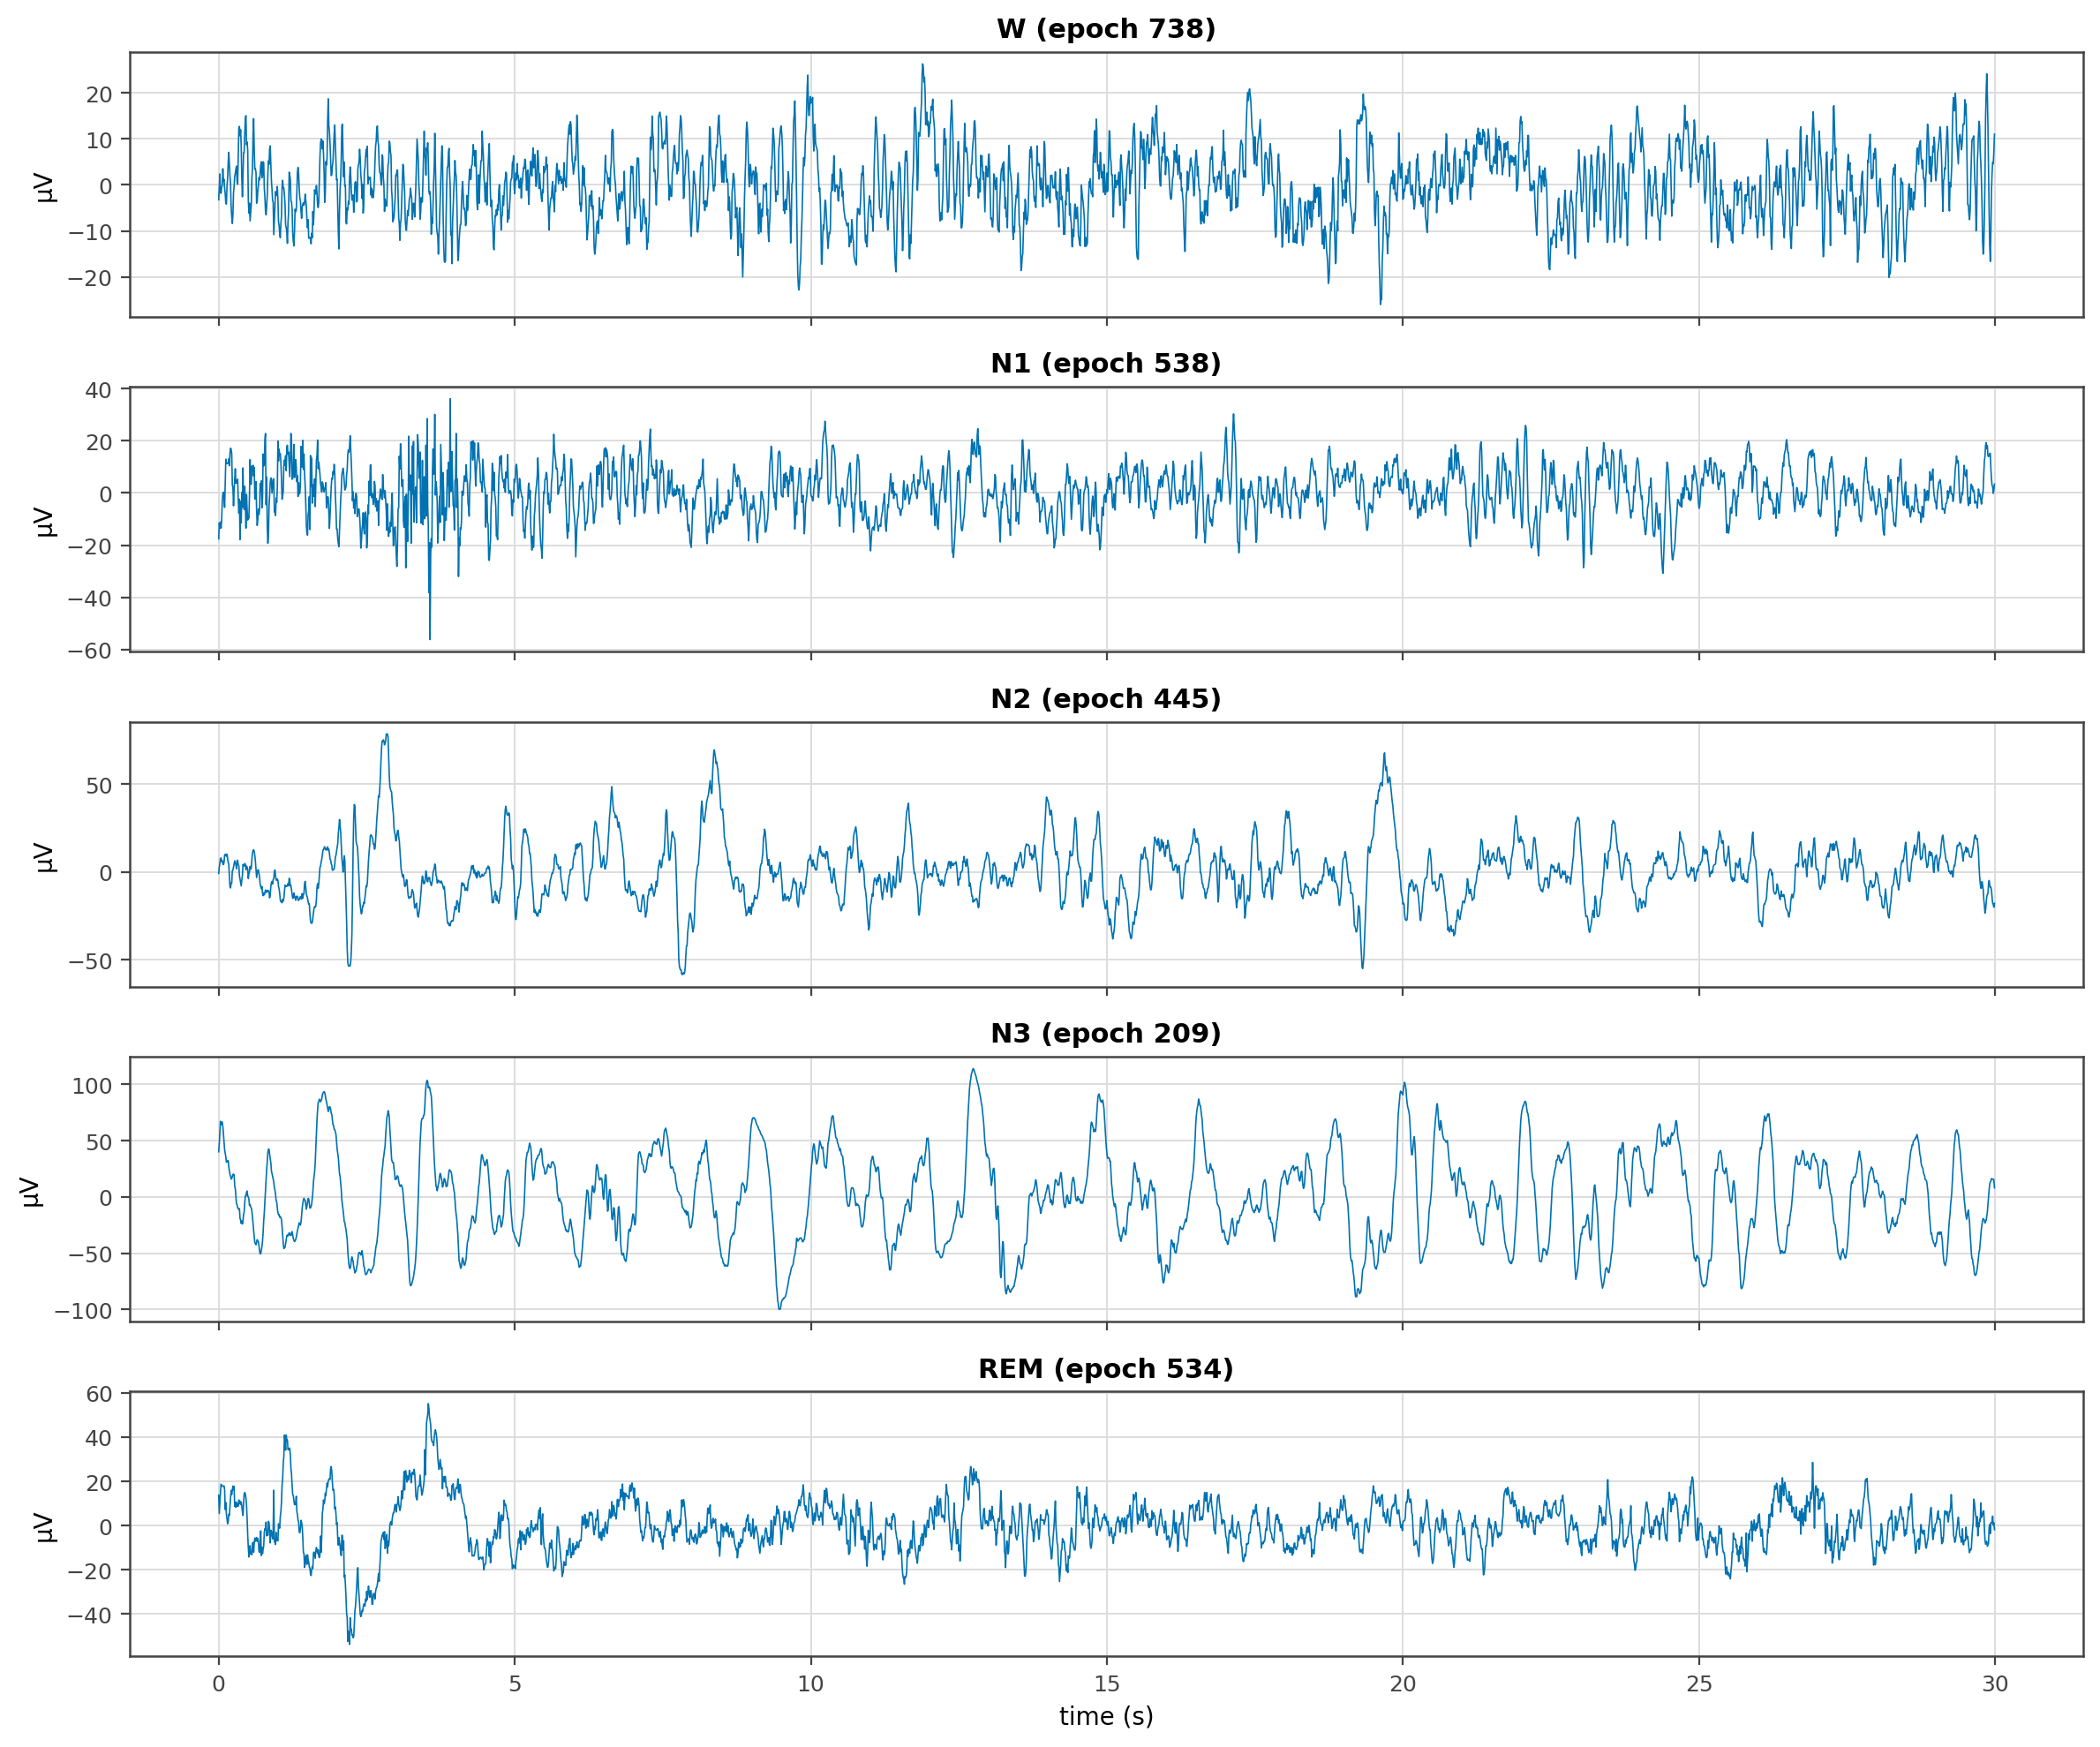

In [6]:
import matplotlib.pyplot as plt
stages = ["W", "N1", "N2", "N3", "REM"]
rec = recs[0]                                   # first cropped night
fs = rec.fs
t = np.arange(rec.epochs["eeg"].shape[1]) / fs

fig, axes = plt.subplots(len(stages), 1, figsize=(12, 10), sharex=True)
for ax, s in zip(axes, stages):
    idx = np.flatnonzero(rec.labels == s)
    if len(idx) == 0:
        ax.set_title(f"{s}: no epochs"); continue
    i = idx[len(idx) // 2]                      # an epoch from the middle of that stage
    ax.plot(t, rec.epochs["eeg"][i] * 1e6, lw=0.6)   # volts -> µV
    ax.set_ylabel("µV"); ax.set_title(f"{s} (epoch {i})")
axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

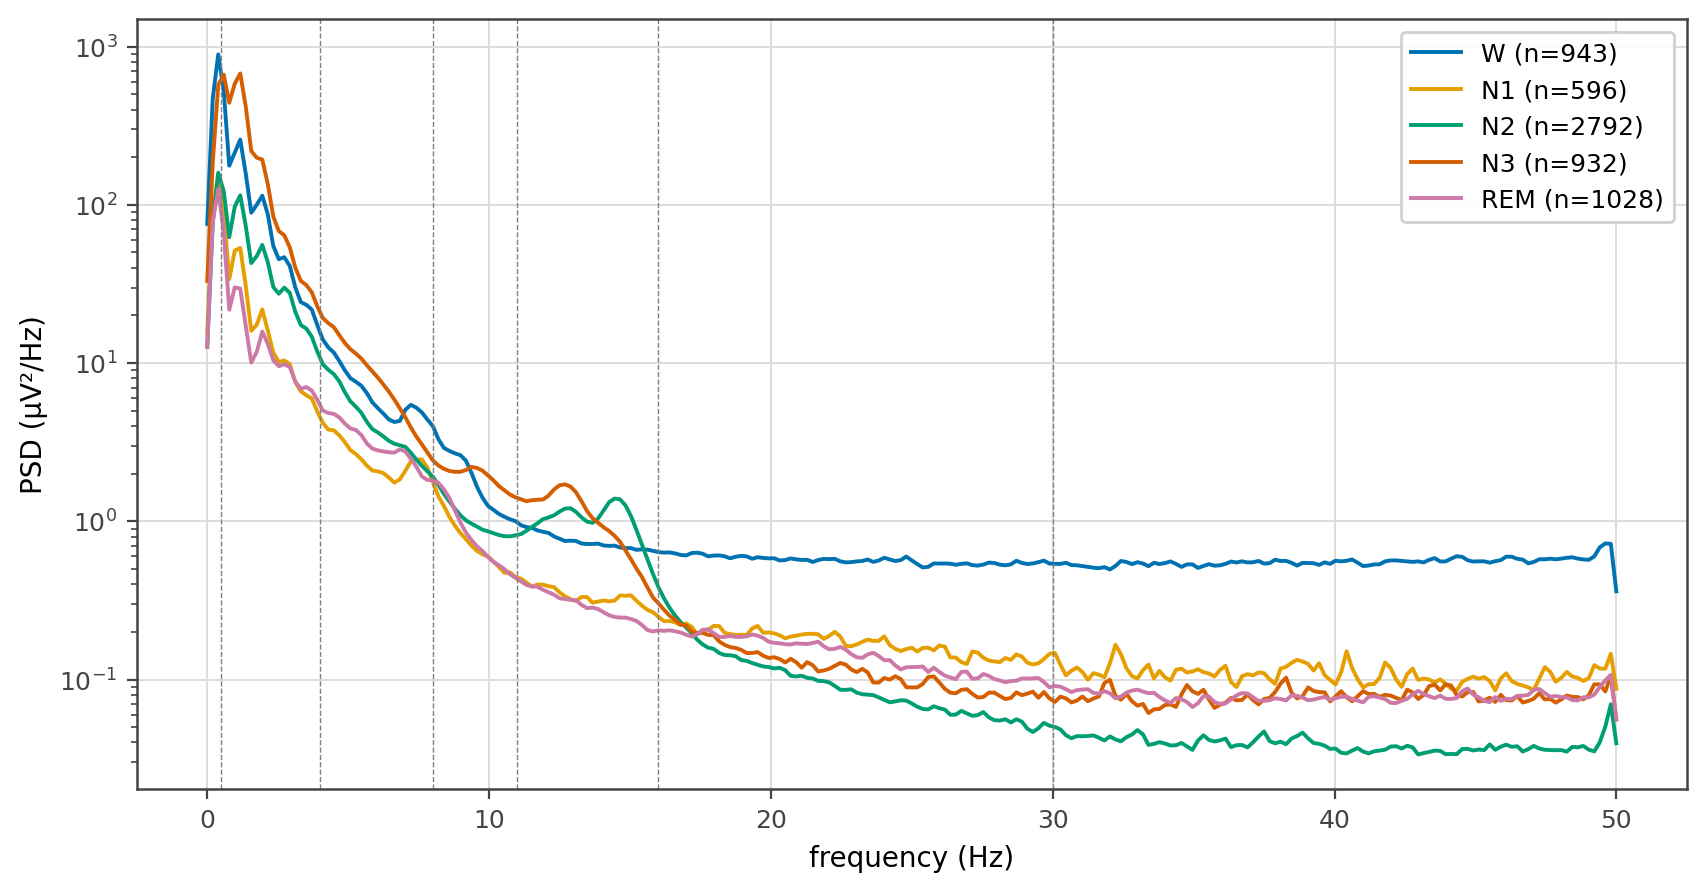

In [7]:
from scipy.signal import welch
plt.figure(figsize=(10, 5))
for s in stages:
    X = np.concatenate([r.epochs["eeg"][np.asarray(r.labels) == s] for r in recs])
    if len(X) == 0: continue
    f, P = welch(X * 1e6, fs=fs, nperseg=512, axis=-1)
    plt.semilogy(f, P.mean(axis=0), label=f"{s} (n={len(X)})")
for b in [0.5, 4, 8, 11, 16, 30]:               # band edges: delta, theta, alpha, sigma, beta
    plt.axvline(b, color="gray", lw=0.5, ls="--")
plt.xlabel("frequency (Hz)"); plt.ylabel("PSD (µV²/Hz)"); plt.legend(); plt.show()

In [8]:
for r in recs:
    eeg = r.epochs["eeg"] * 1e6                 # µV, one row per epoch
    sd = eeg.std(axis=1)
    peak = np.abs(eeg).max(axis=1)
    hi, lo = eeg.max(), eeg.min()
    clipped = ((np.isclose(eeg, hi) | np.isclose(eeg, lo)).sum(axis=1) > 10).sum()
    print(f"{r.meta['record']}: {len(eeg)} epochs | flat (sd<1 µV) {(sd < 1).sum()} | "
          f">500 µV {(peak > 500).sum()} | clipped {clipped} | median peak {np.median(peak):.0f} µV")

SC4001E0: 841 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 0 | median peak 80 µV
SC4002E0: 1127 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 0 | median peak 89 µV
SC4011E0: 1103 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 0 | median peak 66 µV
SC4012E0: 1186 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 0 | median peak 63 µV
SC4021E0: 1025 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 0 | median peak 55 µV
SC4022E0: 1009 epochs | flat (sd<1 µV) 0 | >500 µV 0 | clipped 1 | median peak 74 µV


## 2 · Features + leave-one-subject-out evaluation

In [ ]:
X, y, groups = track.build_dataset(recs)
rep = track.evaluate(X, y, groups)
print(f"split unit : {rep['split_unit']} (n_groups={rep['n_groups']})")
print(f"Cohen's kappa : {rep['cohens_kappa']:.3f}")
print(f"macro-F1      : {rep['macro_f1']:.3f}")
print(f"accuracy      : {rep['accuracy']:.3f}   (compare against kappa -- accuracy alone can be inflated by Wake)")
print('spread        :', rep['summary'])   # the per-subject range -- never the pooled number alone

## Read the number against a yardstick

**Yardstick:** human inter-rater **κ ≈ 0.76**; strong models **κ ≈ 0.79–0.82**. A baseline κ *above* the human ceiling is a **warning** (Wake imbalance / tiny subset), not a triumph. On the real Sleep-EDF data this scaffold has been validated on (4-subject LOSO), the supplied baseline actually reaches **κ = 0.835 / macro-F1 = 0.741** — itself a case of that warning sign (inflated by long Wake stretches and a tiny LOSO), not evidence the problem is easy; full numbers and caveats in [`tracks/sleep_edf_card.md`](https://github.com/farhad-abtahi/CM2013/blob/main/tracks/sleep_edf_card.md). The synthetic cohort here runs at the *medium* rung of the difficulty curriculum on purpose: it lands near κ ≈ 0.6 with a wide per-subject spread, so design choices have somewhere to move.

Accuracy hides class imbalance — always read **κ / macro-F1 / the confusion matrix** together, and state the **split unit** with every number.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ConfusionMatrixDisplay.from_predictions(rep['y_true'], rep['y_pred'], labels=rep['labels'],
        normalize='true', cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f"Sleep stages — LOSO (κ={rep['cohens_kappa']:.2f})"); plt.tight_layout(); plt.show()

## Decision points on this track — the menus you are choosing from

Everything below is a **menu, not a recipe.** `tracks/adapter.py` ships options *with their trade-offs* and no blessed answer; picking one, measuring what it cost or earned, and writing down why is the work the rubric grades (criteria 2 and 5). Below, after one warning you should read first, a cell runs a few of them side by side so you can see that the numbers actually move.

Every option listed here is one **this track's adapter actually reads** — the notebook is generated from the track's own `SUPPORTED_CFG_KEYS`, so nothing below is a decoration.

### Stage 2 — preprocessing · `SleepEDFTrack(cfg={"eeg_band": ..., "notch": ...})`

| choice | buys you | costs you |
|---|---|---|
| `eeg_band=(0.5, 40)` | the §9.6 case-study spec; keeps beta intact | little — but say why 40 and not 35 |
| `eeg_band=(0.5, 30)` | removes EMG bleed and mains entirely | deletes the beta band that some Wake/N1 features lean on |
| `notch=50.0` | free when the hum is narrow-band | pointless if your band never reaches 50 Hz — and harmful if a feature lives near it |
| per-subject z-scoring of band powers | comparability across subjects (this track's biggest spread driver) | erases absolute amplitude, which carries some of N3 |
| artifact handling: reject / interpolate / keep-and-flag | the first loses data, the second invents it, the third pushes the problem into the features | all three defensible — name which and why |
| cropping to lights-off ± 30 min | removes a huge Wake block | changes the class prior, and therefore *every* metric |

### Stage 2, the other way to slice it — **by noise type, not by technique** · `cfg["preprocess"] = "denoise"`

Chapter 8's argument is that you do not choose a filter, you **identify a corruption and then choose its remedy**. §8.11's box is titled *"Identify before you filter"* and closes: *"the noise's signature chooses the tool. Match a narrow, known-frequency artifact to a notch; low-frequency drift to a high-pass; broadband in-band noise to averaging or adaptive filtering; and impulsive outliers to a median — **not the reverse.**"* The epigraph is blunter: *"Removing noise you have not identified is how you accidentally remove signal."*

So `adapter.denoise()` is keyed **one entry per problem**. Run §8.3's three-lens check (time, frequency, what changes across epochs) on a few real epochs first, name what you actually see, then pick a remedy for each:

| Ch. 8 noise type | `cfg` key | options | the trade-off |
|---|---|---|---|
| **Impulsive / electrode pop** (§8.7) | `"impulsive"` | `"median"` | the *only* remedy here that works. §8.7: a linear filter "simply smears the outlier into a blur — **it lets the outlier vote**". A window longer than your narrowest feature flattens that feature |
| **Baseline wander** (§8.8) | `"baseline"` | `"highpass"` · `"detrend"` † · `"wavelet"` † | §8.8: 0.5 Hz is fine for *monitoring*, but a **diagnostic** ECG needs content to 0.05 Hz — too aggressive a corner "can manufacture artificial ST shifts that mimic ischaemia". `"detrend"` avoids the corner and the ringing but happily subtracts a genuine slow physiological trend |
| **Powerline** (§8.6) | `"powerline"` | `"notch"` · `"adaptive"` · `"spectral"` † | §8.6 calls mains "the *friendliest* artifact". `q` is the whole decision: too narrow misses a wandering hum, too wide bites real signal. `"adaptive"` (LMS) tracks drift a fixed notch cannot; `"spectral"` avoids time-domain ringing but needs the frequency resolution to isolate the bins |
| **Broadband / white** (§8.4) | `"broadband"` | `"movavg"` · `"savgol"` · `"wavelet"` · `"gaussian"` | §8.4 is honest that there is no cure: "the only clean weapons against it are averaging and improving the acquisition hardware." `"savgol"` (§9.7) "smooths broadband noise while largely preserving the height, width, and area of peaks"; `"wavelet"` (§10.6) keeps sharp transients best; both still ignore outliers |

**Order is fixed and it is not arbitrary:** `impulsive → baseline → powerline → broadband`. §9.7 is explicit that "impulse removal must precede any linear filtering" — a spike is broadband, so a notch or band-pass cannot delete it, it "only smears the spike across a wide neighbourhood". Pass `broadband="median"` and the harness moves it to the impulsive stage and tells you it did.

> † These three are **extensions beyond the book** — Chapter 8 names only high-pass/detrend, notch, median, and averaging/adaptive. Polynomial and wavelet baseline removal and spectral interpolation are standard practice but are not in the text: use them if you can defend them, and cite something other than the book.

§8.2 asks the prior question too: is this segment *noisy*, or *broken*? "bad segments should be detected and excluded or flagged, **not silently filtered**" — filtering "quietly manufactures a plausible-looking trace out of garbage, and every downstream number inherits the fiction."

### Stage 3 — spectral estimation · `cfg["spectral_method"]`, `cfg["ar_order"]`, `cfg["mt_bandwidth"]`

Every band-power feature is an integral under a **power spectral density** — and the PSD is not a fact you look up, it is an **estimate**. Which estimator produced it is a design decision with the same standing as the band edges (Chapter 7).

§7.2's verdict on the naive option is that the periodogram is **inconsistent**: *"As N grows, we get more frequency bins, but the scatter around the true value at each bin **does not decrease**."* A longer record buys finer bin spacing and no extra reliability. §7.4 then names the law the whole non-parametric family obeys: *"Bartlett's method converts the useless variance of the periodogram into usable smoothness, paid for in resolution. **This resolution-variance trade-off is the governing law of non-parametric spectral estimation.**"*

| `spectral_method` | Type | Variance | Resolution | Best when |
|---|---|---|---|---|
| `"periodogram"` | non-parametric | high (**inconsistent**) | ≈ 1/T | "never for features; a baseline" (§7.16) — run it to be *beaten* |
| `"bartlett"` | non-parametric | ≈ 1/K | ≈ K/T (coarser) | long record, simple averaging; the trade in its purest form |
| `"welch"` *(default)* | non-parametric | ≈ 1/K | tunable via `nperseg` | "long, stationary record — the workhorse" (§7.16) |
| `"multitaper"` | non-parametric | ≈ 1/K, K ≈ 2NW−1 | full-record, set by NW | "short record, want low-leakage smooth PSD (EEG/neuro)" — averages orthogonal Slepian/DPSS tapers over the **whole** record instead of chopping it |
| `"ar"` | **parametric** (Burg) | low, smooth | very high (sub-1/T) | "short segment, resonant rhythm" — a mu peak or an HRV peak you intend to *locate* |

**The AR risk, in §7.9's words:** *"Choose it too low and the spectrum is over-smoothed — real peaks merge or vanish (**under-fitting**). Choose it too high and the model starts fitting noise, sprouting **spurious peaks** that are not in the true spectrum (**over-fitting**)."* At order 40 on the book's EEG epoch the curve "breaks out in a rash of small peaks that are artifacts of over-fitting, not physiology" — and your band powers will faithfully integrate them. Select the order with AIC/MDL, and keep §7.9's rule of thumb (p ≲ N/3, usually far less).

§7.9's decision framework is the sentence to quote in your report: *"if you have a long, stationary record, use non-parametric Welch — the everyday workhorse; if you have a short segment, use parametric AR (Burg or Yule-Walker) for its resolution — and choose the order carefully."* Multitaper sits between: assumption-light like Welch, but often the better non-parametric choice on short segments *"where Welch runs out of segments to average"*.

### Stage 4 — feature selection · `cfg["select"]`, `cfg["select_k"]`, `cfg["select_C"]`

| `select` | Family | Picks features by | Good when | Watch out |
|---|---|---|---|---|
| `"none"` *(default)* | — | keeps everything | few features vs. many samples; you want the model to arbitrate | irrelevant features dilute distance-based learners |
| `"variance"` | filter | dropping near-constant columns | a cheap sanity pass | says nothing about relevance to `y` |
| `"anova"` | filter | univariate F-test vs. the label | fast and stable on tiny folds | blind to feature *interactions* |
| `"mutual_info"` | filter | non-linear dependence with the label | non-monotonic relations | noisier estimate; wants more samples |
| `"tree"` | embedded | forest impurity importance | interactions matter | biased toward continuous/high-cardinality features; **splits credit** between correlated features so near-duplicates survive together |
| `"lasso"` | embedded | L1-penalised linear SVM — coefficients driven to **exactly zero** | you want genuine sparsity and a short, defensible feature list; redundant correlated features should be *eliminated* | assumes roughly **linear** separability; among two correlated features L1 keeps one near-arbitrarily, so **check the surviving set is stable across folds** before calling it "the" feature set |

**`"tree"` vs `"lasso"` is the contrast worth running.** Both are *embedded*, so both see interactions a univariate filter cannot. But on correlated features they behave oppositely: a forest **splits the credit** (two near-duplicate band powers each get half the importance and both survive), while L1 **picks one and zeroes the other** (a second copy of an already-used feature buys no likelihood and costs penalty). `"tree"` gives you a ranking with the redundancy intact; `"lasso"` gives you a genuinely short list. `select_C` is the L1 strength — *smaller C = fewer surviving features* — and it is a number you must report.

**`select_k` is clamped to this track's feature count, out loud.** The default `select_k = 20` is larger than the feature count on four of the six tracks, so a naive first experiment would keep every feature and quietly teach you that selection does nothing. The harness now says so — watch for the `[Track] select=...` line and check `rep["notes"]`. The two **embedded** options ignore `select_k` entirely: how many features survive is a *result*, and the harness prints it.

### Stage 5 — class imbalance · `cfg["imbalance"]`, `cfg["threshold"]`

The supplied baseline uses `class_weight="balanced"`. That is a **default, not a recommendation**, and the rubric grades how you addressed imbalance — so make it a choice you can defend:

| `imbalance` | What it does | Watch out |
|---|---|---|
| `"none"` | plain majority vote | the rare class can be predicted almost never while accuracy still looks fine |
| `"balanced"` *(default)* | per-class weights ∝ 1/frequency | amplifies noisy minority rows too; probabilities stop being calibrated |
| `"balanced_subsample"` | as above, recomputed per tree | forest-specific |
| `"resample"` | random over-sampling **inside `fit`** | duplicated rows invite overfitting — and outside the fold it is a *leak* |
| `"smote"` | **synthetic** minority rows, interpolated between a real sample and one of its k nearest minority neighbours (fold-safe, inside `fit`) | a point halfway between two epochs is a claim about feature space, **not about physiology** — interpolate between two different patients, or an N2 and an N3 epoch, and you have manufactured a body that does not exist. On these small cohorts that risk is live |
| `"adasyn"` | as `"smote"`, concentrated where the minority is hardest to classify | densifies exactly the contested boundary, so mislabelled or artifactual minority rows get amplified most |
| `"threshold"` | move the operating point on the minority class | you must report the threshold; tuning it on test data is as dishonest as a leak |

**The distinction to state in your report:** `"balanced"` never adds a row, it changes how much each existing row *counts*. `"resample"` adds exact copies, so the minority region gets heavier but not one millimetre wider. `"smote"` adds **new points in feature space**, so the region genuinely expands and the boundary is pushed rather than weighted — which is the whole benefit and the whole danger. If you use it, say what a synthetic minority sample *means* on your track, and be honest if the answer is "nothing physiological".

Doing nothing is a defensible answer *if you say you looked and why you left it*. A silent default is worth no marks.

> **Two things the wrapper does for you, and both are worth understanding.** `"resample"`, `"smote"` and `"adasyn"` are all applied **inside `fit`**, so they are redone per fold on training rows only — resampling before the split puts copies (or interpolations) of the test rows into the training set and the score becomes fiction. And SMOTE/ADASYN run **after** the pipeline's `StandardScaler` (`scale → resample → clf`), because "k nearest minority neighbours" is a statement about *distance*: search in raw units and whichever feature happens to be measured in the largest numbers picks the neighbours, regardless of physiological similarity. In Colab the setup cell installs `imbalanced-learn` for you; every other option on this menu is sklearn-only.

### Read downstream symptoms **backwards**, to the stage that caused them

The reflex when a number disappoints is to retune the classifier (stage 5). It is usually the wrong stage. Diagnose upwards:

| What the report shows | The tempting fix | Where the cause usually is |
|---|---|---|
| **Worst-subject metric far below the mean** (check `rep['summary']` and `rep['spread_rows']`) | more trees, deeper trees | **Stage 2 — preprocessing.** A per-recording normalisation, a different band, or artifact handling. A feature that means different things in different subjects cannot be rescued by a classifier. Then **stage 4**: a selector fit on a majority of easy subjects can drop the only feature the hard one needed. |
| **Good pooled metric, one class near-zero recall** | accept it; the average looks fine | **Stage 5 — imbalance handling** first (the menu above), then **stage 3**: if no feature actually describes that class, no weighting invents one. |
| **Feature selection changed nothing at all** | conclude selection is useless here | **`select_k` ≥ your feature count** — the harness prints a note saying exactly this. Lower `select_k` before drawing any conclusion. |
| **A leaky split scores far above the honest one** | quietly report the higher number | **Validation, stage 1.** The split unit is the deployment claim. This gap is the size of the lie. |
| **Train ≫ test, and the spread across groups is huge** | regularise the model | **Stage 3 — feature extraction.** Too many features for the number of *independent groups* (not rows). Fewer, better-motivated features beat more regularisation. |

> **Log it.** Copy [`tracks/results_log_TEMPLATE.md`](https://github.com/farhad-abtahi/CM2013/blob/main/tracks/results_log_TEMPLATE.md) into your team repo as `RESULTS.md` and add a row per iteration *plus* a decision-log row per choice above. Rubric **Criterion 9 — Iteration & revision history** is graded from that file, and it specifically asks for at least one decision you went back and **revised because of a downstream result** — not just more iterations forward.

### ⚠️ Read this **before** you run the next cell

**Comparing many options against the same folds is itself a way to overfit.** The cell below scores several design choices on the *same* group-aware folds — and those are the same folds that will produce the number you report. No individual run leaks a subject; the harness guarantees that. But if you try twelve configurations against one held-out set and then report the best, the winner is chosen partly because it suits *these particular subjects*, and its margin over the runner-up is optimistically biased. This is the **garden of forking paths**: the leak is not in any one fold, it is in the *selection* you perform across many of them. It gets worse the more you look, and it is invisible — the report comes out looking exactly like an honest one.

Which is why this warning is here rather than under the results: the decisions that fix it can only be made **before you know which option won**. Take one minute now and write down:

1. **How many configurations you will compare** — a handful, not a sweep. Put the list in `RESULTS.md` *before* you run it, and report the count in your report.
2. **Whether you are holding out a DEV set** — a few groups set aside up front, so the comparison and the final number do not come from the same folds.
3. **What you will count as a difference** — a margin smaller than the spread across subjects (the `worst / best` columns the cell prints) is *no difference*, not a win.

The trade-offs of those two approaches are laid out in full just after the cell. Read them now if you want the argument first; the point is that the choice between them is only honest while you still cannot see the table.

In [ ]:
# A/B the SAME honest harness under different design choices. None of these is
# "the answer" -- the point is that the numbers MOVE, so the choice is a real one
# with a consequence you can measure and defend.
X, y, groups = track.build_dataset(recs)
PRIMARY = track.meta.default_metrics[0]

options = [
    ('supplied baseline', {}),
    ('select=anova, default k=20', {'select': 'anova'}),
    ('select=anova, k=6', {'select': 'anova', 'select_k': 6}),
    ('select=tree', {'select': 'tree'}),
    ('imbalance=none', {'imbalance': 'none'}),
    ('select=lasso (L1, C=1.0)', {'select': 'lasso'}),
    ('imbalance=smote', {'imbalance': 'smote'}),
    ('preprocess: band-pass 0.5-30 Hz', {'eeg_band': (0.5, 30.0), 'rebuild': True}),
    ('preprocess: wavelet denoise (db4)', {'preprocess': 'wavelet', 'rebuild': True}),
    ('preprocess: by noise type (Ch.8)', {'preprocess': 'denoise', 'impulsive': 'median', 'baseline': 'highpass', 'powerline': 'notch', 'rebuild': True}),
    ('spectral: multitaper band power', {'spectral_method': 'multitaper', 'rebuild': True}),
    ('spectral: AR/Burg (order 16)', {'spectral_method': 'ar', 'rebuild': True}),
    ('spectral: raw periodogram', {'spectral_method': 'periodogram', 'rebuild': True}),
]
rows, unit = [], None
for name, c in options:
    c = dict(c)
    # a PREPROCESSING choice changes the features themselves, so stages 2-3 must
    # re-run; a selection/imbalance choice only changes stages 4-5 inside the folds.
    if c.pop("rebuild", False):
        Xc, yc, gc = track.build_dataset(recs, cfg=c)
    else:
        Xc, yc, gc = X, y, groups
    r = track.evaluate(Xc, yc, gc, cfg=c)
    sp = r["spread"].get(PRIMARY, {})
    unit = r["spread_unit"]      # subject / record / fold -- whichever the metric is defined on
    rows.append((name, r[PRIMARY], sp.get("min", float("nan")), sp.get("max", float("nan"))))

print(f"\n{'design choice':<38} {PRIMARY:>12}   worst / best {unit}")
print("-" * 82)
for name, val, lo, hi in rows:
    print(f"{name:<38} {val:>12.3f}   {lo:.3f} / {hi:.3f}")

print("\nHarness notes (things it refuses to hide):")
for n in track.notes or ["(none)"]:
    print("  *", n)

Read the table above as a **decision record in progress**, not a leaderboard. Two things to notice: the `select_k = 20` row is a *no-op* (this track has ~11 features — the harness note says so), and the band-pass row moves the number more than any selector does. That is the shape of this track: **preprocessing and features are where the marks are**, and the worst-subject column is where the next iteration's question comes from. If your worst subject sits far below the mean, go back to stage 2 (per-subject normalisation) before you touch stage 5.

### Now you have the table — two things it does *not* protect you from

**1 · The forking-paths problem you were warned about, in full.**
Every row in that table was scored on the *same* group-aware folds — and those are the same folds that will produce the number you report. A dozen comparisons on a cohort of five subjects is a lot of selection pressure on very little data.

Two defensible ways to handle it, either of which is worth marks if you say which you used:

| approach | what you do | what it costs |
|---|---|---|
| **a separate development set** | hold out a few groups *up front* as a DEV set, compare every design option on DEV only, then run the winner **once** on the untouched evaluation folds and report that number | fewer groups for both purposes — painful on the small cohorts here, and the DEV estimate is noisy |
| **a comparison budget** | decide in advance how many configurations you will compare (a handful, not a sweep), write them into `RESULTS.md` *before* you run them, and report the count | you may miss a better option; you must resist re-opening the budget after seeing the numbers, which is the whole discipline |

Whichever you choose, **report the number of configurations you compared**, and read a small margin (a couple of points, inside the per-group spread) as *no difference* rather than as a win. A difference smaller than the spread across subjects is not a result. If you have just run the cell above without deciding any of this first, the honest move is to write down the count you have already spent and adopt a budget from here on — not to keep comparing until something wins.

**2 · Features here are built BEFORE the folds are cut — which is safe only because nothing learns.** `build_dataset()` runs stages 2-3 over every recording once, and `evaluate()` splits afterwards. Every preprocessing option on the menus above is **stateless** (a fixed filter, or a threshold estimated from one epoch's own samples), so computing it before or inside the fold gives identical features and the ordering is purely a speed decision.

That stops being true the moment you add a stage that **learns from the data** — a **CSP** spatial filter, a PCA/ICA basis, a z-score whose mean and scale come from the pooled cohort, a learned artifact template. Fit any of those over all the recordings first and every held-out subject has already shaped the transform that built the training features. **The harness will not catch this**: `assert_no_subject_leak` checks group ids per fold, and it cannot see that a filter was learned from them, so the number comes out clean and wrong. A learned stage must be fit *inside* the fold — as a step in the `clf=` pipeline (cloned and refit per fold) or via `select_features()` — and you should say in `RESULTS.md` which you did.

### ⚠️ The one thing above that is **not** a menu — see the leak once

Every table above is a genuine choice you get to make and defend. **The validation scheme is not one.** The leakage-safe split — LOSO or GroupKFold on this track's declared split unit — is the only number that counts for your grade, and `TrackAdapter.evaluate()` enforces it on every fold with `assert_no_subject_leak`. There is no config key to turn it off, deliberately.

So why run the wrong one at all? Because **seeing the gap once is the fastest way to understand why.** The cell below scores this track's data twice: once with a naive random stratified 5-fold split that ignores the leakage unit entirely, and once with the honest group-aware split. Same features, same classifier, same metric. The only difference is *who is allowed to appear on both sides of the split* — and the difference between the two numbers is the size of the claim you would be making falsely.

Predict the gap before you run it.

In [ ]:
# NOT A CHOICE. The honest split is the only one that counts for your grade --
# but seeing the gap once is the fastest way to understand why.
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from adapter import metrics_for

PRIMARY = track.meta.default_metrics[0]
X, y, groups = track.build_dataset(recs)          # rebuilt so this cell stands alone

# 1) THE LEAKY SPLIT -- random/stratified, blind to the leakage unit. Rows from the
#    same subject/record land on BOTH sides, so the model can recognise the person
#    instead of the phenomenon.
leaky_pred = cross_val_predict(track.baseline(), X, y,
                               cv=StratifiedKFold(5, shuffle=True, random_state=0))
leaky = metrics_for(y, leaky_pred)[PRIMARY]

# 2) THE HONEST SPLIT -- the scaffold's own group-aware LOSO / GroupKFold.
honest = track.evaluate(X, y, groups)[PRIMARY]

unit = track.meta.split_unit
rows_per_group = np.bincount(np.unique(groups, return_inverse=True)[1])
gap = leaky - honest
print(f"leaky  random 5-fold split      : {PRIMARY} = {leaky:.3f}   <-- NOT a deployment claim")
print(f"honest {unit + '-wise split':<24} : {PRIMARY} = {honest:.3f}   <-- the number that counts")
print(f"{'gap (the size of the lie)':<32} : {gap:+.3f}")
print(f"{'rows per ' + unit:<32} : max {rows_per_group.max()}, median {int(np.median(rows_per_group))}")
print()

if rows_per_group.max() == 1:
    print(f"READ IT HONESTLY: on this track every {unit} contributes exactly ONE row, so a random")
    print(f"  split CANNOT put the same {unit} on both sides. There is structurally nothing to")
    print( "  leak here, and the gap is expected to be ~0 (what you see is just fold-composition")
    print( "  noise, and it can even come out negative). This is not evidence that leakage is a")
    print( "  non-issue in biosignals -- it is this track's granularity making it impossible.")
    print(f"  The tracks with many epochs per {unit} are where the gap opens up; go look at one.")
elif gap >= 0.05:
    print(f"READ IT HONESTLY: each {unit} contributes up to {rows_per_group.max()} rows, so a random split")
    print(f"  scatters one {unit}'s rows across train AND test. The model scores partly by")
    print(f"  recognising the {unit} -- which at deployment is a {unit} it has never seen.")
    print(f"  That {gap:+.3f} is the size of the claim you would be making falsely.")
else:
    print(f"READ IT HONESTLY -- and this is the interesting case. Each {unit} contributes up to")
    print(f"  {rows_per_group.max()} rows, so a leak WAS structurally possible, and yet the gap is only {gap:+.3f}.")
    print( "  The tempting conclusion ('leakage does not matter here') is the wrong one. What a")
    print(f"  near-zero gap actually says is that the current features carry little {unit}-specific")
    print( "  structure for the model to memorise -- which, when the honest score is also close to")
    print( "  chance, usually means they are not carrying much of ANYTHING yet.")
    print( "  So this is a statement about your feature set, not a licence to split randomly.")
    print( "  RE-RUN THIS CELL after you improve stage 2/3 (e.g. a CSP spatial filter, per-subject")
    print( "  normalisation): the better your features get at describing the individual, the wider")
    print( "  this gap will open -- which is exactly when an honest split starts to matter most.")
print()
print("Rule: the split unit IS the deployment claim. State it with every number you report.")

**Whatever gap you just measured, the honest number is the one that goes in your report** — and rubric **Criterion 8** exists to catch a report that quotes the flattering one.

Read the printed diagnosis rather than just the number, because a near-zero gap means two very different things depending on the track:

| what you see | what it means |
|---|---|
| **a large positive gap** (sleep, HAR, EMG — the epoch-per-subject tracks) | the leak is real and you just measured it. On EMG it is the largest in the scaffold, because overlapping windows from one contraction are nearly copies of each other |
| **~zero gap, one row per group** (ECG, CTG — record-level tracks) | structurally impossible to leak: each record contributes a single row, so no record can straddle the split. A fact about granularity, **not** a licence to split randomly on your next dataset |
| **~zero gap, many rows per group** (BCI) | the honest-looking case that is actually a warning. A leak *was* possible and did not happen, which means the features currently carry little subject-specific structure — and with a score near chance, not much of anything else either. **Re-run the cell after you add CSP or per-subject normalisation**: as the features get better at describing the individual, this gap opens up, which is precisely when the honest split starts to matter most |

Two things worth writing down in `RESULTS.md` while you have the numbers in front of you: what you *predicted* the gap would be, and which real-world claim the leaky number would have been. "93 % accurate at detecting this condition" and "93 % accurate **on people it has already seen**" are different sentences, and only one of them is a product.

## 3 · Reporting (module 7) — confusion matrix, hypnogram, clinical summaries

`tracks/report.py` is the shared reporting stage: `summarize_results()` leads with the confusion matrix and the metric **with its spread**, `plot_hypnogram()` draws predicted vs. reference, `compare_stage_summaries()` checks the night-level numbers a clinician reads. Restyle any of it — it is a starting point, not a required figure format.

In [ ]:
import report as R
# Hold out the WORST subject, not the first one: report.py already tells you to
# 'read this one's errors before the mean's', and a night-level summary computed on
# an easy subject agrees perfectly and teaches nothing.
worst = min((r for r in rep['spread_rows'] if np.isfinite(r.get('cohens_kappa', np.nan))),
            key=lambda r: r['cohens_kappa'])['group']
te = np.flatnonzero(groups == worst); tr = np.flatnonzero(groups != worst)
model = track.baseline().fit(X[tr], y[tr]); pred = model.predict(X[te])
R.plot_hypnogram(y[te], pred, epoch_seconds=30,
                 title=f'Hypnogram — worst held-out subject {worst}'); plt.show()
print(f'\nNight-level summaries for {worst} (per-epoch kappa was the cohort minimum):')
_ = R.compare_stage_summaries(y[te], pred)   # TST, sleep efficiency, WASO, SOL, REM latency
print('\n§16.5: a decent per-epoch kappa can still mis-estimate what a clinician reads.')

## 4 · Hold-out submission (`record,epoch,label`)

In [ ]:
import tempfile
model = track.train_baseline(recs[:-1])
out = os.path.join(tempfile.gettempdir(), 'sleep_predictions.csv')
track.write_submission(recs[-1:], out, model)
print(open(out).read().splitlines()[:6])

## Reflect & improve

1. **Was your prediction right?** If the real number surprised you, *why*?
2. **Answer the guiding questions above** in your report — that is how you *motivate* your design (L5), not just implement it.
3. **Improve the supplied baseline honestly**: better preprocessing and **feature construction** first (the DSP is the point), then a better model — validated *inside* the folds, keeping the declared split unit. Read your gain against the yardstick.
4. **Go back, don't only go forward.** At least one decision above should end up *revised* because of a number further downstream — that is the loop the capstone is actually about, and rubric **Criterion 9** grades it from your `RESULTS.md` ([`tracks/results_log_TEMPLATE.md`](https://github.com/farhad-abtahi/CM2013/blob/main/tracks/results_log_TEMPLATE.md)). Log the iteration *and* the decision that changed.
5. **Submit** the `predictions.csv` below for hold-out evaluation (`tracks/HOLDOUT_EVALUATION.md`).

---
*Real-data capstone companion for **Biomedical Signal Processing & Data Analytics: From Physiology to Machine Learning**. Synthetic path is reproducible and offline; the real path is an opt-in, agreement-free public dataset. Numbers are honest, not clinical benchmarks. Generated by `tools/build_track_notebooks.py`.*